A **phase portrait** displays the behavior at **one** parameter combination. A **parameter screen** repeats the fixed-point search for every cell of a two-dimensional grid and assigns a color according to the stable expression states found there.

# Code

## Imports

In [3]:
import numpy as np                
import matplotlib.pyplot as plt   
import seaborn as sns             
import scipy                      
import scipy.integrate           
import scipy.optimize            
import scipy.cluster.hierarchy as hcluster  
from scipy.spatial import distance
from scipy.optimize import root
from sklearn.cluster import KMeans  
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import pandas as pd             
import copy                     
from numpy.random import rand    
from numpy import isclose
from IPython.display import display
import warnings

np.random.seed(3)
plt.rcParams['figure.dpi'] = 100

## Zhu et al. Code

In [4]:
def dx_dt(x, t, p):
    """
    ODE
    x = array of TF total
    p = parameters
    """
    Atot, Btot = x
    A2 = 2 * Atot**2 / (p.Kd + 4 * (Atot + Btot) + np.sqrt(p.Kd**2 + 8 * (Atot + Btot) * p.Kd))
    B2 = 2 * Btot**2 / (p.Kd + 4 * (Atot + Btot) + np.sqrt(p.Kd**2 + 8 * (Atot + Btot) * p.Kd))
    return np.array([p.alpha + p.beta * A2**p.n / (1 + A2**p.n) - Atot,
                     p.alpha + p.beta * B2**p.n / (1 + B2**p.n) - Btot])

In [5]:
class BSParams(object):
    """
    Container for parameters for homodimeric bistable circuits.
    """
    def __init__(self, **kwargs):
        # Dimensionless parameters
        self.alpha = 0.8 # leakiness
        self.beta = 20 # Maximal production
        self.Kd = 1 # Dissociation constant of dimers
        self.n = 1 # Additional cooperativity of transcriptional activation
        self.r = 1 # Leakiness ratio
        self.m = 1 # A and B copy number ratio
        self.kappa = 1 # Ratio of A and B's binding affinity with DNA
        self.gamma = 1 # Ratio of stability between A and B

        # Put in params that were specified in input
        for entry in kwargs:
            setattr(self, entry, kwargs[entry])

The four long expressions are analytical partial derivatives of the original ODEs. `np.linalg.eigvals()` calculates their eigenvalues 

A fixed point is locally stable if both real parts are negative. 

In [6]:
def stability(x0, y0, p):
    # x0, y0 = fixed point coord
    # Calculate the stability of fixed point based on eigenvalue of jacobian matrix
    jmat = jacobian(x0, y0, p)
    eig = np.linalg.eigvals(jmat)
    return (np.real(eig)<0).all()

def jacobian(x0, y0, p):
    # Calculate the jacobian matrix
    # Fixed point = (x0, y0)
    # p = parameters
    jmat = np.zeros([2,2])
    sqtemp = np.sqrt(p.Kd**2 + 8 * (x0 + y0) * p.Kd)
    
    jmat[0,0] = - 1 - p.beta * (1 + ((p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * x0**2))**p.n)**(-2) * p.n * ((p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * x0**2))**(p.n-1) * (x0 * (4 + 4 * p.Kd / sqtemp) - 2 * (p.Kd + 4 * (x0 + y0) + sqtemp)) / (2 * x0**3)
    jmat[0,1] = - p.beta * (1 + ((p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * x0**2))**p.n)**(-2) * p.n * ((p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * x0**2))**(p.n-1) * (4 + 4 * p.Kd / sqtemp) / (2 * x0**2)
    jmat[1,0] = - p.m * p.beta * (1 + (p.kappa * (p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * y0**2))**p.n)**(-2) * p.n * (p.kappa * (p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * y0**2))**(p.n-1) * p.kappa * (4 + 4 * p.Kd / sqtemp) / (2 * y0**2)
    jmat[1,1] = - p.gamma - p.m * p.beta * (1 + (p.kappa * (p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * y0**2))**p.n)**(-2) * p.n * (p.kappa * (p.Kd + 4 * (x0 + y0) + sqtemp) / (2 * y0**2))**(p.n-1) * (y0 * p.kappa * (4 + 4 * p.Kd / sqtemp) - 2 * p.kappa * (p.Kd + 4 * (x0 + y0) + sqtemp)) / (2 * y0**3)
    
    return jmat

In [7]:
def GetEndPtPos(dx_dt, x0, t, p):
    """
    Given an initial condition, time and a parameter set, output the position of trajectory endpoint;
    1000 rounds = 5s
    """
    # Integrate the trajectory
    x = scipy.integrate.odeint(dx_dt, x0, t, args=(p,))
    # Retrieve the endpoint
    return x[-1,:]

def GenInitCond(start, end, density, dim):
    """
    Generate initial condition for ODE solver
    """
    x0range = np.array([np.linspace(start, end, density)])
    x0meshgrid = np.meshgrid(*[x0range for i in range(dim)])
    x0 = np.array([np.ndarray.flatten(x0meshgrid[i])+0.05*rand(1)[0] for i in range(dim)])
    return x0

def GenResult(p, t, density, dim):
    """
    Generate endpoint results based on parameters
    """
    # Generate initial condition
    x0 = GenInitCond(p.alpha, p.alpha+p.beta, density, dim)
    result = np.zeros([np.shape(x0)[1], dim])
    for i in range(np.shape(x0)[1]):
        result[i,:] = GetEndPtPos(dx_dt, x0[:,i], t, p)
    return result

def CalFixedPtNum(result, thresh):
    """
    Calculate the number of fixed points
    thresh = threshold for hierachical clustering
    """
    label = hcluster.fclusterdata(result, thresh, criterion="distance")
    return np.max(label)

def CalFixedPts(p, t, x0range, density, thresh):
    """
    Calculate attractor basins for a given p
    """
    # Calculate the total number of fixed point to specify n_clusters for KMean algorithm
    InitialResult = GenResult(p, t, density, 2)
    TotalNumFixedPt = CalFixedPtNum(InitialResult, thresh)
    
    kmeans = KMeans(n_clusters=TotalNumFixedPt, random_state=0).fit(InitialResult)
    
    # Sort Label and fixed points according to their number of TF ON
    temp = np.sum(kmeans.cluster_centers_, axis=1)
    FixedPts = kmeans.cluster_centers_[np.argsort(temp)]
    
    # Double-check stability of each fixed points if number of Stable Fixed Pts > 4 (possible degeneracy)
    if np.shape(FixedPts)[0]>4:
        stable_fp = []
        for i in range(np.shape(FixedPts)[0]):
            if stability(FixedPts[i,0], FixedPts[i,1], p)==1:
                stable_fp.append([FixedPts[i,0], FixedPts[i,1]])
        return np.array(stable_fp)
    else:
        return FixedPts

At the estimated stable states, it checks whether $[A_2]$ and $[B_2]$ exceed 1, and assigns the integer codes 0–5. 

In [8]:
def StabCategory(p, t, x0range, density=8, thresh=1.5, thre=1):
    # Calculate stable fixed points
    stable_fp = CalFixedPts(p, t, x0range, density, thresh)
    # Determine the stability category of the system
    highorlow = np.zeros([len(stable_fp),2])
    # Calculate the A2 and B2 level at stability point
    highorlow[:,0] = 2*stable_fp[:,0]**2/(p.Kd+4*np.sum(stable_fp, axis=1)+
                                          np.sqrt(p.Kd**2+8*np.sum(stable_fp, axis=1)*p.Kd))
    highorlow[:,1] = 2*stable_fp[:,1]**2/(p.Kd+4*np.sum(stable_fp, axis=1)+
                                          np.sqrt(p.Kd**2+8*np.sum(stable_fp, axis=1)*p.Kd))
    # Compare A2 and B2 level with K (TF-DNA binding affinity), which is 1 after non-dimensionalization
    stab_det = np.sum(highorlow>thre,axis=1)
    
    # For any stable fixed point, stab_det = 0 means it is a double negative state
    # For any stable fixed point, stab_det = 1 means it is a single positive state
    # For any stable fixed point, stab_det = 2 means it is a double positive state
    # The return value: 0 = monostability, both low; 1 = monostability, both high, 2 = bistability, 
    # 3 = Type I tristability, 4 = Type II tristability, 5 = quadrastability
    if 0 in stab_det:
        if 1 in stab_det:
            if 2 in stab_det:
                # All 4 stable points = Quadrastability
                return 5, stable_fp
            else:
                # AlowBlow, AhighBlow, AlowBhigh = Type I tristability
                return 3, stable_fp
        else:
            # AlowBlow only = Monostability, both low
            return 0, stable_fp
    else: 
        if 1 in stab_det:
            if 2 in stab_det:
                # AhighBlow, AlowBhigh, AhighBhigh = Type II tristability
                return 4, stable_fp
            else:
                # AhighBlow, AlowBhigh = Bistability
                return 2, stable_fp
        else:
            # AhighBhigh = Monostability, both high
            return 1, stable_fp

At every pair of parameter values, it calls `StabCategory`. `savepd` exports a matrix to CSV. 

In [9]:
def paramscreen(pinit, p1range, p1name, p2range, p2name):
    # p is the parameter container
    # p1range, p2range is the range of two parameters
    # p1name, p2name is the name of two paramters
    rangescale=1.5
    t = np.linspace(0, 250, 250)
    cate = np.zeros([len(p1range), len(p2range)])
    p = copy.copy(pinit)
    for i, p1 in enumerate(p1range):
        if i%10==0:
            print(i)
        if p1name=='expfactor':
            p = copy.copy(pinit)
            setattr(p, 'alpha', p.alpha*p1)
            setattr(p, 'beta', p.beta*p1)
        else:
            setattr(p, p1name, p1)
        for j, p2 in enumerate(p2range):
            if p2name=='expfactor':
                p = copy.copy(pinit)
                setattr(p, p1name, p1)
                setattr(p, 'alpha', p.alpha*p2)
                setattr(p, 'beta', p.beta*p2)
            else:
                setattr(p, p2name, p2)
            A_range = [p.alpha*0.01, rangescale*p.beta]
            B_range = [p.r*p.alpha*0.01, rangescale*p.m*p.beta]
            cate[i,j], StableFixedPts = StabCategory(p, t, A_range)
    return cate

def savepd(data, param1, param2, savedir):
    # Save the parameter screening data
    df = pd.DataFrame(data, index=param1, columns=param2)
    df.to_csv(savedir)

## New version

In [10]:
class ThreeAffinityParams(BSParams):
    """Original BSParams plus three independently adjustable dissociation constants."""
    def __init__(self, KAA=1.0, KBB=1.0, KAB=1.0, **kwargs):
        super().__init__(**kwargs)         # Keep alpha, beta, n, r, m, kappa, gamma from BSParams.
        self.KAA = float(KAA)             # AA homodimer dissociation constant.
        self.KBB = float(KBB)             # BB homodimer dissociation constant.
        self.KAB = float(KAB)             # AB heterodimer dissociation constant.
        if min(self.KAA, self.KBB, self.KAB) <= 0:
            raise ValueError('All three affinities must be positive.')

For a guessed $[AB]$, free $[A]$ and $[B]$ follow from the quadratic solutions. Bisection repeatedly halves the physically allowed range $0\leq[AB]\leq\min([A_{\mathrm{tot}}],[B_{\mathrm{tot}}])$ until the equilibrium condition $[AB]=2[A][B]/K_{AB}$ is satisfied. The final homodimer concentrations are $[A]^2/K_{AA}$ and $[B]^2/K_{BB}$.

In [11]:
def modified_dimers(Atot, Btot, p, steps=48):
    """Compute [A2] and [B2] from total concentrations, via [AB] bisection.

    Inputs may be scalars or NumPy grids (for plotting).
    Returns [A2], [B2], free [A], free [B], and equilibrium [AB].
    """
    Atot, Btot = np.broadcast_arrays(np.asarray(Atot, float),
                                     np.asarray(Btot, float))
    if np.any(Atot < 0) or np.any(Btot < 0):
        Atot = np.maximum(Atot, 0.)
        Btot = np.maximum(Btot, 0.)

    # From mass conservation, 0 <= [AB] <= min([Atot], [Btot]).
    # Start the allowed [AB] interval at zero for every concentration pair.
    lo = np.zeros_like(Atot)
    # [AB] cannot exceed either total concentration keep smaller upperbound
    hi = np.minimum(Atot, Btot)

    # Rearranged quadratic solution for each *free* monomer, at a guessed [AB].
    def free_monomer(amount_not_in_AB, K):
        # This is the stable quadratic formula.
        return 2*amount_not_in_AB / (1 + np.sqrt(1 + 8*amount_not_in_AB/K))

    # Root condition: [AB] - 2[A][B]/KAB = 0.
    # `range(steps)` repeats the search 48 times by default.
    for _ in range(steps):
        # Bisection: guess the midpoint of the currently possible [AB] interval.
        AB = (lo + hi) / 2
        # Using that guess, calculate the free A and B monomers.
        A = free_monomer(Atot - AB, p.KAA)
        B = free_monomer(Btot - AB, p.KBB)
        # Mass-action check: guessed [AB] minus the [AB] predicted by free monomers.
        # A positive error means the guess is too high and negative means too low.
        error = AB - 2*A*B/p.KAB
        # If guess is too low, move the lower bound up to the guessed [AB].
        lo = np.where(error < 0, AB, lo)
        # If guess is too high, move the upper bound down.
        hi = np.where(error >= 0, AB, hi)

    AB = (lo + hi) / 2
    A = free_monomer(Atot - AB, p.KAA)
    B = free_monomer(Btot - AB, p.KBB)
    # Convert the final free monomer values into the active homodimers:
    # [A2]=[A]^2/KAA; [B2]=[B]^2/KBB.
    A2 = A*A/p.KAA
    B2 = B*B/p.KBB
    # Return five concentrations, in the order given in the function docstring.
    return A2, B2, A, B, AB

In [12]:
def modified_df_dt(y, t, p):
    """The authors' same ODE structure, evaluated with modified dimers."""
    Atot, Btot = y
    A2, B2, _, _, _ = modified_dimers(Atot, Btot, p)
    dA = p.alpha + p.beta*A2**p.n/(1 + A2**p.n) - Atot
    dB = p.r*p.alpha + p.m*p.beta*B2**p.n/(p.kappa**p.n + B2**p.n) - p.gamma*Btot
    return [dA, dB] # Return the instantaneous rates for both total concentrations.

Because the ODEs use total concentrations while the new dimerization equations use free monomers, the code first differentiates mass conservation. The inverse of this derivative matrix converts changes in total A/B into changes in free A/B. Matrix multiplication (`@`) then applies the chain rule to the Hill production derivatives, and the degradation derivatives are subtracted. The resulting eigenvalues indicate whether a fixed point is stable.

In [13]:
def modified_jacobian(Atot, Btot, p):
    """Analytical Jacobian with the same free-monomer conservation equations."""
    A2, B2, A, B, AB = modified_dimers(float(Atot), float(Btot), p)
    # Derivatives of the two conservation equations with respect to free [A],[B].
    mass_matrix = np.array([
        [1 + 4*A/p.KAA + 2*B/p.KAB, 2*A/p.KAB],
        [2*B/p.KAB, 1 + 4*B/p.KBB + 2*A/p.KAB]
    ], dtype=float)

    # The chain rule: differentiation of the Hill production terms with respect
    # to free [A] and free [B]; the second line retains the authors' kappa.
    dprodA_dA = (p.beta*p.n*A2**(p.n-1) / (1+A2**p.n)**2) * (2*A/p.KAA)
    dprodB_dB = (p.m*p.beta*p.n*(p.kappa**p.n)*B2**(p.n-1)
                 / (p.kappa**p.n+B2**p.n)**2) * (2*B/p.KBB)

   # Chain rule: derivatives with respect to total A and total B.
   # `np.diag()` places the two production derivatives into a diagonal matrix.
  # `np.linalg.inv(mass_matrix)` calculates the inverse of the mass-conservation derivative matrix. This converts changes in total concentrations into changes in free monomers.
  # `@` performs matrix multiplication, combining these relationships through the chain rule.
    return (np.diag([dprodA_dA, dprodB_dB]) @ np.linalg.inv(mass_matrix)
            - np.diag([1., p.gamma]))


def modified_stability(Atot, Btot, p):
    """Same original stability criterion: both Jacobian eigenvalues negative."""
    return bool((np.real(np.linalg.eigvals(modified_jacobian(Atot, Btot, p))) < 0).all())  # Calculate the two eigenvalues and ask if BOTH real parts are negative.


print('Modified equilibrium functions are defined.')

Modified equilibrium functions are defined.


## Find and classify stable fixed points

We need to find where **both** ODE derivatives vanish. For the original model we solve in total concentrations. For the modified model, we can solve in **free monomers** and convert back using mass conservation.

A multistable system has several fixed points. Numerical root-finding from just one starting guess could miss some. The code rejects negative concentrations, checks that each solution actually satisfies both equations, removes duplicates, and tests stability using the corresponding Jacobian. For modified fixed points, free A/B are already known: `modified_jacobian_from_free()` evaluates **the same analytic Jacobian** directly, without rerunning bisection for every root.

In [14]:
# Efficient evaluation of the SAME analytic Jacobian when free A and B are already known from the fixed-point search. This avoids unnecessarily running 48 bisection iterations again for every candidate root.
def modified_jacobian_from_free(A, B, p):
    mass_matrix = np.array([
        [1 + 4*A/p.KAA + 2*B/p.KAB, 2*A/p.KAB],
        [2*B/p.KAB, 1 + 4*B/p.KBB + 2*A/p.KAB]
    ], dtype=float)
    A2, B2 = A*A/p.KAA, B*B/p.KBB
    dprodA_dA = p.beta*p.n*A2**(p.n-1)/(1+A2**p.n)**2 * 2*A/p.KAA
    dprodB_dB = (p.m*p.beta*p.n*p.kappa**p.n*B2**(p.n-1)
                 /(p.kappa**p.n+B2**p.n)**2) * 2*B/p.KBB
    return np.diag([dprodA_dA, dprodB_dB]) @ np.linalg.inv(mass_matrix) - np.diag([1.,p.gamma])

# 0 means below threshold, 1 means above threshold.
# The pair (1,0) means A-high/B-low. 
STATE_NAMES = {(0,0): 'low/low', (1,0): 'A-only', (0,1): 'B-only', (1,1): 'A+B'}

CATEGORY_NAMES = {
    0: 'Low monostability', 1: 'High monostability', 2: 'Bistability',
    3: 'Type I tristability', 4: 'Type II tristability',
    5: 'Quadrastability', 6: 'Other combination'
}
CATEGORY_PATTERNS = {
    frozenset({(0,0)}): 0,
    frozenset({(1,1)}): 1,
    frozenset({(1,0), (0,1)}): 2,
    frozenset({(0,0), (1,0), (0,1)}): 3,
    frozenset({(1,0), (0,1), (1,1)}): 4,
    frozenset({(0,0), (1,0), (0,1), (1,1)}): 5,
}


def get_fixed_points(p, modified=False, nstarts=7):
    """Find numerical fixed points; list entries: Atot, Btot, stable, A2, B2."""
    upper = max(1.0, p.alpha + p.beta, p.r*p.alpha + p.m*p.beta)
    if modified:
        guesses = np.geomspace(.025, max(1., np.sqrt(upper*max(p.KAA,p.KBB))), nstarts)
        def residual(concentrations):
            A, B = concentrations
            if A < 0 or B < 0:
                return np.array([A - abs(A) - 1, B - abs(B) - 1])*100
            A2, B2 = A*A/p.KAA, B*B/p.KBB
            AB = 2*A*B/p.KAB
            Atot = A + 2*A2 + AB
            Btot = B + 2*B2 + AB
            return np.array([
                p.alpha + p.beta*A2**p.n/(1+A2**p.n) - Atot,
                p.r*p.alpha + p.m*p.beta*B2**p.n/(p.kappa**p.n+B2**p.n) - p.gamma*Btot
            ])
    else:
        guesses = np.geomspace(.025, upper, nstarts)
        def residual(concentrations):
            A, B = concentrations   # Here A,B denote *TOTAL* concentrations.
            if A < 0 or B < 0:
                return np.array([A - abs(A) - 1, B - abs(B) - 1])*100
            return np.asarray(dx_dt([A,B],0.,p),dtype=float)

    roots = []
    for first_guess in guesses:
        for second_guess in guesses:
            # scipy.optimize.root repeatedly adjusts the two guesses until BOTH
            # derivatives approach zero (NOT a time simulation or bisection).
            result = root(residual, [first_guess,second_guess], method='hybr',
                          options={'maxfev':700})
            if not result.success or np.linalg.norm(residual(result.x)) > 1e-5:
                continue
            if min(result.x) < 0:
                continue

            if modified:
                A, B = result.x
                A2, B2 = A*A/p.KAA, B*B/p.KBB
                AB = 2*A*B/p.KAB
                Atot, Btot = A+2*A2+AB, B+2*B2+AB
                stable = bool((np.real(np.linalg.eigvals(modified_jacobian_from_free(A,B,p)))<0).all())
            else:
                Atot, Btot = result.x
                den = p.Kd + 4*(Atot+Btot) + np.sqrt(p.Kd**2+8*p.Kd*(Atot+Btot))
                A2, B2 = 2*Atot**2/den, 2*Btot**2/den
                stable = bool(stability(Atot,Btot,p))

            if not any(np.linalg.norm(np.array([Atot,Btot])-np.array(old[:2]))<1e-3
                       for old in roots):
                roots.append([float(Atot),float(Btot),bool(stable),float(A2),float(B2)])
    return roots


def classify_states(points):
    """Return author category (0-5) or 6 when asymmetry creates another pattern."""
    # Only stable fixed points count towards multistability.
    stable = [r for r in points if r[2]]
    patterns = frozenset((int(r[3]>1.), int(r[4]>1.)) for r in stable)
    # Require the exact expected state pattern, not just the same number of points.
    category = CATEGORY_PATTERNS.get(patterns,6)
    return category, len(stable), patterns

print('New fixed-point finder and state classifier ready.')

New fixed-point finder and state classifier ready.


## Validation 

In [15]:
# Compare at several total concentrations, including asymmetric A/B inputs.
probe = [0.1, 0.5, 1., 3., 6., 12., 20.]
X, Y = np.meshgrid(probe, probe)

for Kd in [0.3, 1.0, 2.0]:
    original = BSParams(alpha=.8, beta=20., Kd=Kd, n=1.5)
    equal = ThreeAffinityParams(alpha=.8, beta=20., Kd=Kd, n=1.5,
                                KAA=Kd, KBB=Kd, KAB=Kd)
    den = Kd + 4*(X+Y) + np.sqrt(Kd*Kd+8*Kd*(X+Y))
    original_A2, original_B2 = 2*X**2/den, 2*Y**2/den
    new_A2, new_B2, _, _, _ = modified_dimers(X,Y,equal)
    assert np.allclose(original_A2,new_A2,rtol=1e-10,atol=1e-10)
    assert np.allclose(original_B2,new_B2,rtol=1e-10,atol=1e-10)

    for x,y in [(0.7,0.9),(2.,5.),(6.,12.),(15.,20.)]:
        assert np.allclose(dx_dt([x,y],0.,original), modified_df_dt([x,y],0.,equal),
                           atol=1e-9,rtol=1e-9)
        assert np.allclose(jacobian(x,y,original), modified_jacobian(x,y,equal),
                           atol=1e-7,rtol=1e-7)
    print(f'PASS: dimers + ODEs + Jacobian match for KAA=KBB=KAB={Kd:g}')

# Check a key regime where the original phase portrait has three stable points.
original = BSParams(alpha=.8,beta=20.,Kd=1.,n=1.5)
equal = ThreeAffinityParams(alpha=.8,beta=20.,Kd=1.,n=1.5,KAA=1.,KBB=1.,KAB=1.)
r_orig=get_fixed_points(original, nstarts=10)
r_eq=get_fixed_points(equal,modified=True,nstarts=10)
co,so,po=classify_states(r_orig)
ce,se,pe=classify_states(r_eq)
assert (co,so,po)==(ce,se,pe)
assert so==3, (so,se)
assert len(r_orig)==len(r_eq)
from scipy.optimize import linear_sum_assignment
D=np.linalg.norm(np.asarray([r[:2] for r in r_orig])[:,None,:]
                -np.asarray([r[:2] for r in r_eq])[None,:,:],axis=-1)
ii,jj=linear_sum_assignment(D)
assert np.max(D[ii,jj]) < 1e-4
assert all(r_orig[i][2]==r_eq[j][2] for i,j in zip(ii,jj))
print(f'PASS: original/equal-affinity fixed points agree; {so} stable states.')

PASS: dimers + ODEs + Jacobian match for KAA=KBB=KAB=0.3
PASS: dimers + ODEs + Jacobian match for KAA=KBB=KAB=1
PASS: dimers + ODEs + Jacobian match for KAA=KBB=KAB=2
PASS: original/equal-affinity fixed points agree; 3 stable states.


In [16]:
AFFINITY_CASES = [
    dict(name='AA favored', KAA=0.3, KBB=1.0, KAB=1.0),
    dict(name='Both homodimers favored', KAA=0.3, KBB=0.3, KAB=1.0),
    dict(name='Heterodimer favored', KAA=1.0, KBB=1.0, KAB=0.3),
]
RELATIVE_TO_ORIGINAL_KD = True  # True: use K factors times original Kd.


SCREEN_N = 20
SEARCH_STARTS = 6           

# Same category codes as the authors, with an extra code 6 for asymmetric cases.
CATEGORY_COLORS = sns.color_palette('viridis', 7)
SCREEN_CMAP = ListedColormap(CATEGORY_COLORS)
SCREEN_NORM = BoundaryNorm(np.arange(-.5,7.5,1), SCREEN_CMAP.N)

for case in AFFINITY_CASES:
    print(f"{case['name']:<26} KAA={case['KAA']} KBB={case['KBB']} KAB={case['KAB']}")

AA favored                 KAA=0.3 KBB=1.0 KAB=1.0
Both homodimers favored    KAA=0.3 KBB=0.3 KAB=1.0
Heterodimer favored        KAA=1.0 KBB=1.0 KAB=0.3


## Screen function where two parameters varied at once


In [17]:
def parameters_for_screen(alpha=.8,beta=20.,Kd=1.,n=1.5,
                          KAA=None,KBB=None,KAB=None,modified=False):
    common = dict(alpha=float(alpha),beta=float(beta),Kd=float(Kd),n=float(n),
                  r=1.,m=1.,kappa=1.,gamma=1.)
    if not modified:
        return BSParams(**common)
    return ThreeAffinityParams(
        KAA=Kd if KAA is None else KAA,
        KBB=Kd if KBB is None else KBB,
        KAB=Kd if KAB is None else KAB,
        **common
    )


def scan_two_parameters(p1name, p1values, p2name, p2values, *,
                        base=None, modified=False, nstarts=SEARCH_STARTS):
    """Return screen category, number of stable points, and exact state patterns."""
    if base is None:
        base = dict(alpha=.8,beta=20.,Kd=1.,n=1.5,KAA=1.,KBB=1.,KAB=1.)
    categories = np.zeros((len(p1values), len(p2values)), dtype=int)
    counts = np.zeros_like(categories)
    identities = [[None for _ in p2values] for _ in p1values]
    for i, first_value in enumerate(p1values):
        for j, second_value in enumerate(p2values):
            # Make a fresh dictionary so changing one pixel never changes another.
            settings = dict(base)
            settings[p1name] = float(first_value)
            settings[p2name] = float(second_value)
            p = parameters_for_screen(**settings, modified=modified)
            points = get_fixed_points(p, modified=modified, nstarts=nstarts)
            categories[i,j], counts[i,j], identities[i][j] = classify_states(points)
    return categories, counts, identities


def draw_screen(ax, matrix, p1name, p1values, p2name, p2values, title):
    """Seaborn heatmap: rows = p1; columns = p2, same category colors everywhere."""
    sns.heatmap(matrix, ax=ax, cmap=SCREEN_CMAP, norm=SCREEN_NORM,
                cbar=False, linewidths=0, square=True)
    # Show just a few real parameter values so labels remain legible.
    row_ix=np.unique(np.linspace(0,len(p1values)-1,4).astype(int))
    col_ix=np.unique(np.linspace(0,len(p2values)-1,4).astype(int))
    ax.set_yticks(row_ix+.5, labels=[f'{p1values[k]:.2g}' for k in row_ix])
    ax.set_xticks(col_ix+.5, labels=[f'{p2values[k]:.2g}' for k in col_ix])
    ax.tick_params(axis='y',labelrotation=0)
    ax.tick_params(axis='x',labelrotation=45)
    ax.set_ylabel(p1name)
    ax.set_xlabel(p2name)
    ax.set_title(title,fontsize=10,pad=10)


def show_category_legend(fig, top=0.89):
    patches=[Patch(color=CATEGORY_COLORS[i],label=f'{i}: {CATEGORY_NAMES[i]}') for i in range(7)]
    fig.legend(handles=patches, loc='lower center', ncol=4,
               bbox_to_anchor=(.5,-.06),fontsize=9,frameon=False)

print('Screen and heatmap functions ready.')

Screen and heatmap functions ready.


## Original $\alpha$ vs $\beta$ screen

We vary $\alpha$ and $\beta$ over the authors' original ranges, while $n=1.5$ and $K_d=1$ stay fixed. Each modified panel holds the displayed $K_{AA},K_{BB},K_{AB}$ values constant across its screen.

The first two panels should be identical. 

PASS: equal-affinity full screen: 400/400 cells agree.


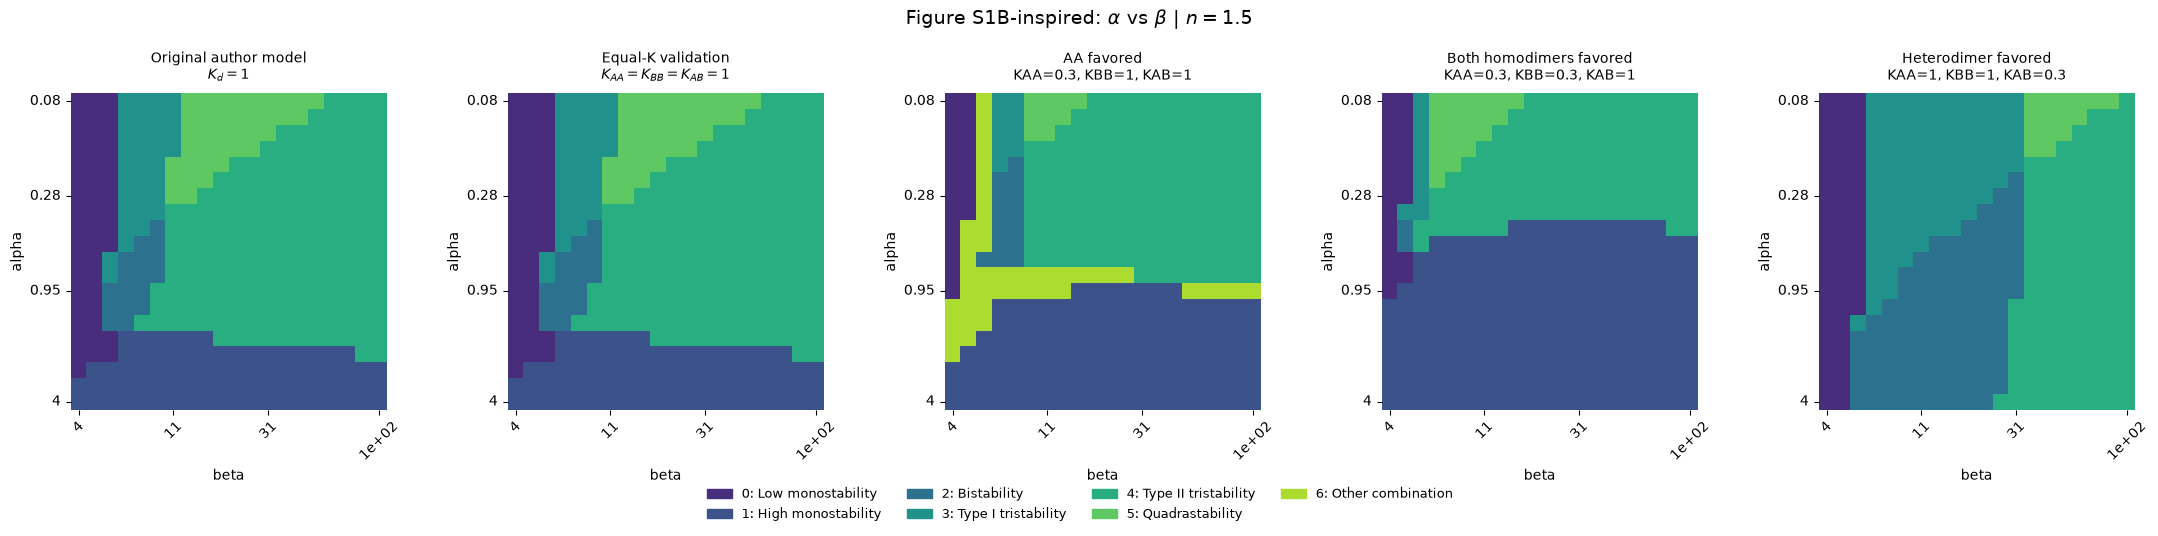

In [19]:
alpha_values = np.geomspace(.08, 4., SCREEN_N)  
beta_values = np.geomspace(4., 100., SCREEN_N) 

original_screen, original_counts, original_signatures = scan_two_parameters(
    'alpha', alpha_values, 'beta', beta_values, modified=False)
equal_screen, equal_counts, equal_signatures = scan_two_parameters(
    'alpha', alpha_values, 'beta', beta_values, modified=True)

assert np.array_equal(original_screen, equal_screen)
assert np.array_equal(original_counts, equal_counts)
assert all(original_signatures[i][j]==equal_signatures[i][j]
           for i in range(SCREEN_N) for j in range(SCREEN_N))
print(f'PASS: equal-affinity full screen: {SCREEN_N**2}/{SCREEN_N**2} cells agree.')

screens = [original_screen, equal_screen]
labels = ['Original author model\n$K_d=1$',
          'Equal-K validation\n$K_{AA}=K_{BB}=K_{AB}=1$']
for case in AFFINITY_CASES:
    scale = 1. if not RELATIVE_TO_ORIGINAL_KD else 1.0  # Kd=1 in this example.
    base = dict(alpha=.8,beta=20.,Kd=1.,n=1.5,
                KAA=case['KAA']*scale,KBB=case['KBB']*scale,KAB=case['KAB']*scale)
    category, _, _ = scan_two_parameters('alpha', alpha_values, 'beta', beta_values,
                                         base=base, modified=True)
    screens.append(category)
    labels.append(case['name'] + '\n' +
                  f"KAA={base['KAA']:g}, KBB={base['KBB']:g}, KAB={base['KAB']:g}")

fig, axes=plt.subplots(1,5,figsize=(22,4.8))
for ax, category, label in zip(axes,screens,labels):
    draw_screen(ax,category,'alpha',alpha_values,'beta',beta_values,label)
fig.suptitle(r'$\alpha$ vs $\beta$ | $n=1.5$',fontsize=14,y=1.03)
show_category_legend(fig)
plt.tight_layout(rect=(0,.09,1,.97))
plt.savefig('MF2_Parameter_Alpha_Beta_Five_Panel.png',dpi=160,bbox_inches='tight')
plt.show()

## Strength of both homodimers versus AB

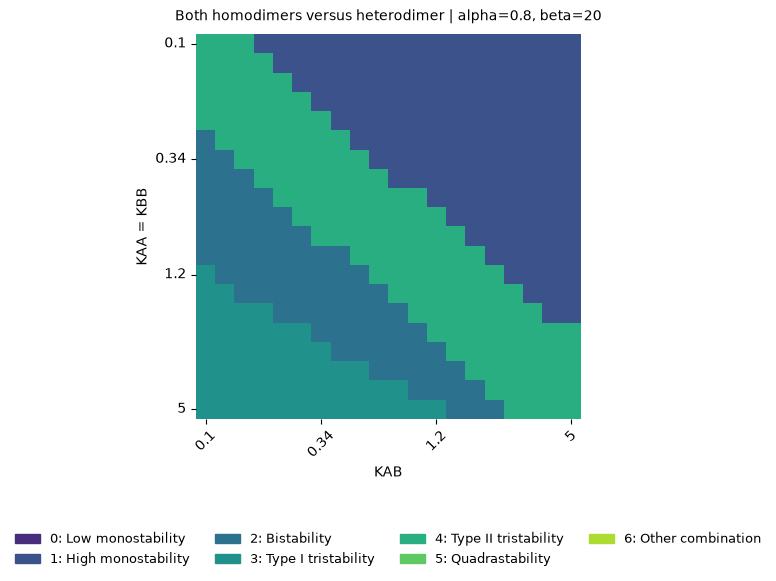

In [20]:
homodimer_values = np.geomspace(.1, 5., SCREEN_N)
KAB_values = np.geomspace(.1, 5., SCREEN_N)

# In each pixel set KAA=KBB=homodimer_K, while KAB is independently chosen.
homo_AB_screen = np.empty((SCREEN_N,SCREEN_N), dtype=int)
homo_AB_counts = np.empty_like(homo_AB_screen)
for i, homodimer_K in enumerate(homodimer_values):
    for j, KAB in enumerate(KAB_values):
        p=parameters_for_screen(modified=True,KAA=homodimer_K,
                                KBB=homodimer_K,KAB=KAB)
        category, count, _=classify_states(get_fixed_points(p,modified=True,
                                                           nstarts=SEARCH_STARTS))
        homo_AB_screen[i,j]=category
        homo_AB_counts[i,j]=count
fig,ax=plt.subplots(figsize=(7,5.5))
draw_screen(ax,homo_AB_screen,'KAA = KBB',homodimer_values,'KAB',KAB_values,
            'Both homodimers versus heterodimer')
show_category_legend(fig)
plt.tight_layout(rect=(0,.09,1,1))
plt.savefig('MF2_Parameter_Homodimers_vs_Heterodimer.png',dpi=160,bbox_inches='tight')
plt.show()

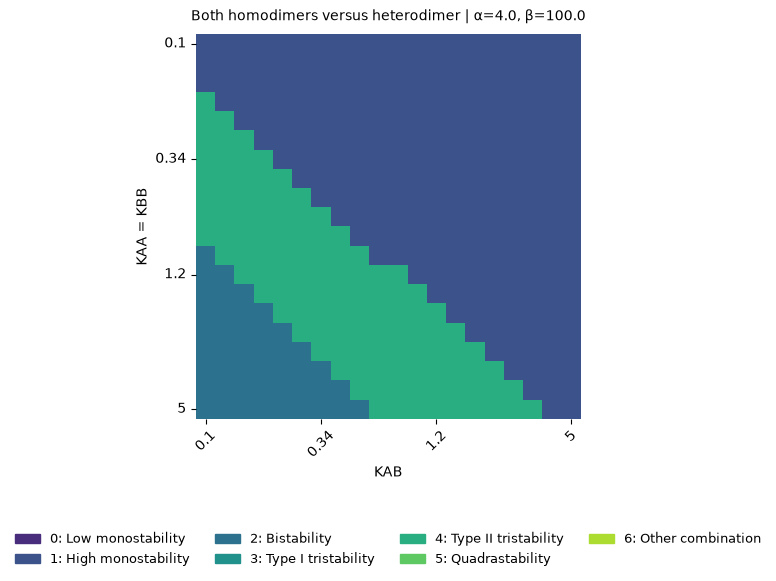

In [25]:
# Fixed parameters
alpha = 4.
beta = 100.
Kd = 1.
n = 1.5

# Parameter ranges
homodimer_values = np.geomspace(.1, 5., SCREEN_N)
KAB_values = np.geomspace(.1, 5., SCREEN_N)

# In each pixel set KAA=KBB=homodimer_K,
# while KAB is independently chosen.
homo_AB_screen = np.empty((SCREEN_N, SCREEN_N), dtype=int)
homo_AB_counts = np.empty_like(homo_AB_screen)

for i, homodimer_K in enumerate(homodimer_values):
    for j, KAB in enumerate(KAB_values):

        p = parameters_for_screen(
            alpha=alpha,
            beta=beta,
            Kd=Kd,
            n=n,
            modified=True,
            KAA=homodimer_K,
            KBB=homodimer_K,
            KAB=KAB
        )

        category, count, _ = classify_states(
            get_fixed_points(
                p,
                modified=True,
                nstarts=SEARCH_STARTS
            )
        )

        homo_AB_screen[i, j] = category
        homo_AB_counts[i, j] = count

# Plot
fig, ax = plt.subplots(figsize=(7, 5.5))

draw_screen(
    ax,
    homo_AB_screen,
    'KAA = KBB',
    homodimer_values,
    'KAB',
    KAB_values,
    f'Both homodimers versus heterodimer | α={alpha}, β={beta}'
)

show_category_legend(fig)

plt.tight_layout(rect=(0, .09, 1, 1))

plt.savefig(
    f'MF2_Homodimers_vs_Heterodimer_alpha{alpha}_beta{beta}.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

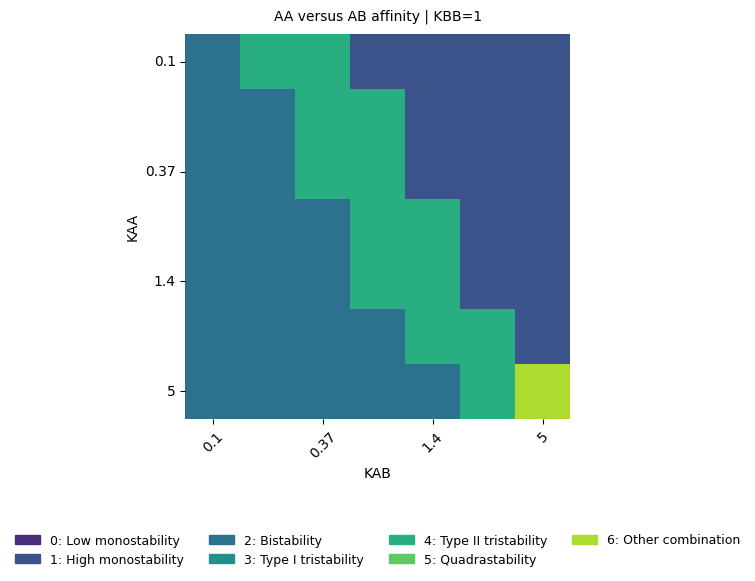

In [19]:
KAA_values_C = np.geomspace(.1, 5., SCREEN_N)
KAB_values_C = np.geomspace(.1, 5., SCREEN_N)
AA_AB_screen, AA_AB_counts, AA_AB_patterns = scan_two_parameters(
    'KAA',KAA_values_C,'KAB',KAB_values_C,
    base=dict(alpha=.8,beta=20.,Kd=1.,n=1.5,KAA=1.,KBB=1.,KAB=1.),modified=True)
fig,ax=plt.subplots(figsize=(7,5.5))
draw_screen(ax,AA_AB_screen,'KAA',KAA_values_C,'KAB',KAB_values_C,
            'AA versus AB affinity | KBB=1')
show_category_legend(fig)
plt.tight_layout(rect=(0,.09,1,1))
plt.savefig('MF2_Parameter_KAA_vs_KAB.png',dpi=160,bbox_inches='tight')
plt.show()